In [1]:
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", palette="viridis")

DATA_DIR = Path.cwd()
if not (DATA_DIR / "hackathon_preli_dataset_-_bangladesh_dengue_large_dataset.csv").exists():
    DATA_DIR = DATA_DIR / "Trial"

RAW_PATH = DATA_DIR / "hackathon_preli_dataset_-_bangladesh_dengue_large_dataset.csv"
PROCESSED_PATH = DATA_DIR / "bangladesh_dengue_preprocessed.csv"
MODELS_DIR = DATA_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

raw_df = pd.read_csv(RAW_PATH)
print(f"Loaded raw dataset: {RAW_PATH.name} -> {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print("Missing values:", int(raw_df.isna().sum().sum()))
print("Exact duplicates:", int(raw_df.duplicated().sum()))
display(raw_df.head(5))

Loaded raw dataset: hackathon_preli_dataset_-_bangladesh_dengue_large_dataset.csv -> 31,320 rows x 12 columns
Missing values: 0
Exact duplicates: 0


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0


In [2]:
def build_multiweek_lag_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """Programmatically compute grouped multi-week weather lags, rolling rainfall sums,
    calendar features, city codes, and 2-to-4-week early-warning targets per ward_id."""
    work = df.copy()
    work["city"] = work["city"].astype(str).str.strip()
    work["ward_id"] = work["ward_id"].astype(str).str.strip()
    work["date"] = pd.to_datetime(work["date"], errors="raise")
    work = work.drop_duplicates(subset=["city", "ward_id", "date"])
    work = work.sort_values(["ward_id", "date"]).reset_index(drop=True)

    grp = work.groupby("ward_id", group_keys=False)

    for lag in range(1, 7):
        work[f"rain_lag{lag}"] = grp["rainfall_mm"].shift(lag)

    for lag in range(1, 9):
        work[f"temp_lag{lag}"] = grp["avg_temp_c"].shift(lag)
        work[f"hum_lag{lag}"] = grp["relative_humidity_pct"].shift(lag)

    work["rain_sum2w"] = work["rainfall_mm"] + work["rain_lag1"]
    work["rain_sum3w"] = work["rain_sum2w"] + work["rain_lag2"]
    work["rain_sum4w"] = work["rain_sum3w"] + work["rain_lag3"]

    work["cases_lag1"] = grp["dengue_cases"].shift(1)
    work["cases_lag2"] = grp["dengue_cases"].shift(2)

    work["target_2w"] = grp["dengue_cases"].shift(-2)
    work["target_3w"] = grp["dengue_cases"].shift(-3)
    work["target_4w"] = grp["dengue_cases"].shift(-4)

    work["week_of_year"] = work["date"].dt.isocalendar().week.astype(int)
    work["month"] = work["date"].dt.month
    city_map = {c: idx for idx, c in enumerate(sorted(work["city"].unique()))}
    work["city_code"] = work["city"].map(city_map).astype(int)

    work = work.dropna().reset_index(drop=True)
    return work


lag_df = build_multiweek_lag_dataset(raw_df)
print(f"Lag pipeline output shape: {lag_df.shape[0]:,} rows x {lag_df.shape[1]} columns")
print(f"Date range: {lag_df['date'].min().date()} to {lag_df['date'].max().date()} ({lag_df['ward_id'].nunique()} wards)")
print(f"Total missing values: {int(lag_df.isna().sum().sum())}")
display(lag_df.head(5))

Lag pipeline output shape: 30,600 rows x 45 columns
Date range: 2016-02-29 to 2025-12-01 (60 wards)
Total missing values: 0


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases,rain_lag1,rain_lag2,rain_lag3,rain_lag4,rain_lag5,rain_lag6,temp_lag1,hum_lag1,temp_lag2,hum_lag2,temp_lag3,hum_lag3,temp_lag4,hum_lag4,temp_lag5,hum_lag5,temp_lag6,hum_lag6,temp_lag7,hum_lag7,temp_lag8,hum_lag8,rain_sum2w,rain_sum3w,rain_sum4w,cases_lag1,cases_lag2,target_2w,target_3w,target_4w,week_of_year,month,city_code
0,2016-02-29,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.22,29.47,19.23,5.89,55.06,0,3.61,8.19,4.17,0.94,1.52,0.00,22.66,60.54,23.56,52.70,24.55,49.88,22.39,60.50,21.75,69.02,20.94,60.50,21.24,61.63,18.32,59.24,9.50,17.69,21.86,0.0,0.0,0.0,0.0,0.0,9,2,0
1,2016-03-07,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.71,31.31,21.56,0.00,64.79,0,5.89,3.61,8.19,4.17,0.94,1.52,25.22,55.06,22.66,60.54,23.56,52.70,24.55,49.88,22.39,60.50,21.75,69.02,20.94,60.50,21.24,61.63,5.89,9.50,17.69,0.0,0.0,0.0,0.0,0.0,10,3,0
2,2016-03-14,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.80,32.82,21.54,2.68,62.29,0,0.00,5.89,3.61,8.19,4.17,0.94,25.71,64.79,25.22,55.06,22.66,60.54,23.56,52.70,24.55,49.88,22.39,60.50,21.75,69.02,20.94,60.50,2.68,8.57,12.18,0.0,0.0,0.0,0.0,0.0,11,3,0
3,2016-03-21,Chattogram,CCC_Ward_01,64024,0.87,0.46,26.37,30.18,19.64,0.00,62.55,0,2.68,0.00,5.89,3.61,8.19,4.17,25.80,62.29,25.71,64.79,25.22,55.06,22.66,60.54,23.56,52.70,24.55,49.88,22.39,60.50,21.75,69.02,2.68,2.68,8.57,0.0,0.0,0.0,0.0,0.0,12,3,0
4,2016-03-28,Chattogram,CCC_Ward_01,64024,0.87,0.46,26.01,31.69,21.28,0.00,66.45,0,0.00,2.68,0.00,5.89,3.61,8.19,26.37,62.55,25.80,62.29,25.71,64.79,25.22,55.06,22.66,60.54,23.56,52.70,24.55,49.88,22.39,60.50,0.00,2.68,2.68,0.0,0.0,0.0,0.0,0.0,13,3,0


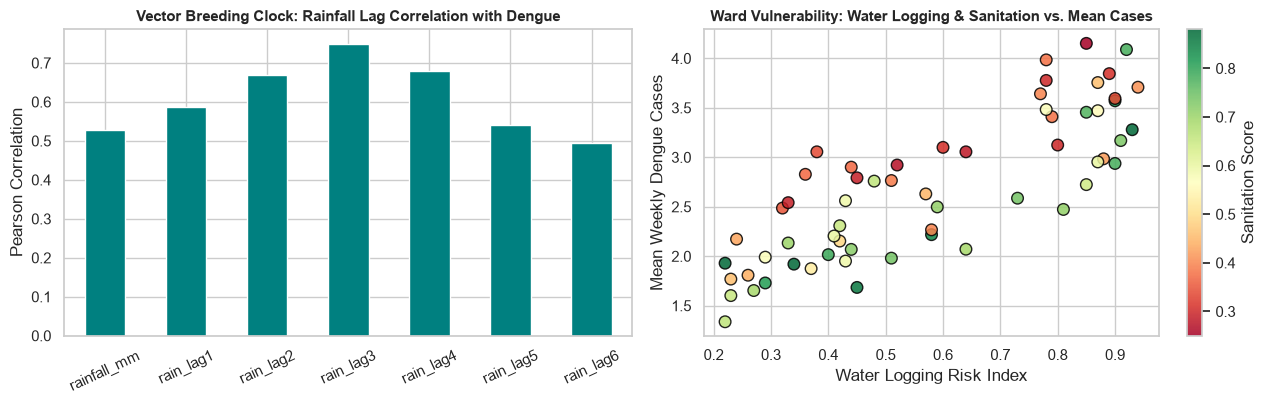

In [3]:
rain_lag_cols = ["rainfall_mm", "rain_lag1", "rain_lag2", "rain_lag3", "rain_lag4", "rain_lag5", "rain_lag6"]
lag_corrs = lag_df[rain_lag_cols].corrwith(lag_df["dengue_cases"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
lag_corrs.plot(kind="bar", color="teal", ax=axes[0], edgecolor="white")
axes[0].set_title("Vector Breeding Clock: Rainfall Lag Correlation with Dengue", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Pearson Correlation")
axes[0].tick_params(axis="x", rotation=25)

ward_summary = lag_df.groupby("ward_id")[["water_logging_risk_index", "sanitation_score", "dengue_cases"]].mean()
sc = axes[1].scatter(
    ward_summary["water_logging_risk_index"],
    ward_summary["dengue_cases"],
    c=ward_summary["sanitation_score"],
    cmap="RdYlGn",
    s=70,
    edgecolor="black",
    alpha=0.85,
)
plt.colorbar(sc, ax=axes[1], label="Sanitation Score")
axes[1].set_title("Ward Vulnerability: Water Logging & Sanitation vs. Mean Cases", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Water Logging Risk Index")
axes[1].set_ylabel("Mean Weekly Dengue Cases")

plt.tight_layout()
plt.show()

In [4]:
from sklearn.preprocessing import MinMaxScaler

lag_df["year"] = lag_df["date"].dt.year
non_feature_cols = {"date", "year", "city", "ward_id", "dengue_cases", "target_2w", "target_3w", "target_4w"}
feature_cols = [c for c in lag_df.columns if c not in non_feature_cols]
print(f"Predictor features count: {len(feature_cols)}")

train_df = lag_df[lag_df["year"] <= 2023].copy()
val_df = lag_df[lag_df["year"] == 2024].copy()
test_df = lag_df[lag_df["year"] == 2025].copy()

print(f"Train (2016-2023)     : {len(train_df):,} rows ({train_df['date'].min().date()} -> {train_df['date'].max().date()})")
print(f"Validation (2024)     : {len(val_df):,} rows ({val_df['date'].min().date()} -> {val_df['date'].max().date()})")
print(f"Held-Out Test (2025)  : {len(test_df):,} rows ({test_df['date'].min().date()} -> {test_df['date'].max().date()})")

scaler_export = MinMaxScaler(feature_range=(0, 1), clip=True)
scaler_export.fit(train_df[feature_cols])

export_df = lag_df.drop(columns=["year"]).copy()
export_df[feature_cols] = scaler_export.transform(export_df[feature_cols])
export_df["date"] = export_df["date"].dt.strftime("%Y-%m-%d")
export_df.to_csv(PROCESSED_PATH, index=False)

assert export_df.isna().sum().sum() == 0
print(f"Saved leakage-free [0, 1]-scaled multi-lag dataset to: {PROCESSED_PATH} ({export_df.shape})")

Predictor features count: 38
Train (2016-2023)     : 24,540 rows (2016-02-29 -> 2023-12-25)
Validation (2024)     : 3,180 rows (2024-01-01 -> 2024-12-30)
Held-Out Test (2025)  : 2,880 rows (2025-01-06 -> 2025-12-01)


Saved leakage-free [0, 1]-scaled multi-lag dataset to: C:\Users\LENOVO\OneDrive\Documents\Phishing Detection Website\Trial\bangladesh_dengue_preprocessed.csv ((30600, 45))


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

def make_classifiers():
    return {
        "XGBoost": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", XGBClassifier(
                n_estimators=250, max_depth=6, learning_rate=0.05,
                subsample=0.85, colsample_bytree=0.85,
                eval_metric="logloss", random_state=42, n_jobs=-1,
            )),
        ]),
        "LightGBM": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", LGBMClassifier(
                n_estimators=250, max_depth=8, learning_rate=0.05,
                num_leaves=31, subsample=0.85, colsample_bytree=0.85,
                random_state=42, n_jobs=-1, verbose=-1,
            )),
        ]),
        "HistGradientBoosting": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", HistGradientBoostingClassifier(max_iter=200, max_depth=8, learning_rate=0.06, random_state=42)),
        ]),
        "Random Forest": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", RandomForestClassifier(n_estimators=150, max_depth=16, min_samples_leaf=2, random_state=42, n_jobs=-1)),
        ]),
        "Logistic Regression": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", LogisticRegression(C=2.0, max_iter=1500, random_state=42)),
        ]),
        "Naive Bayes (GaussianNB)": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", GaussianNB()),
        ]),
        "Naive Bayes (MultinomialNB)": Pipeline([
            ("scaler", MinMaxScaler(feature_range=(0, 1), clip=True)),
            ("clf", MultinomialNB(alpha=1.0)),
        ]),
    }

horizons = ["target_2w", "target_3w", "target_4w"]
X_train, X_val, X_test = train_df[feature_cols], val_df[feature_cols], test_df[feature_cols]

cls_benchmark_rows = []
best_classifiers = {}
classifiers_2w = {}
test_preds_2w = {}

for horizon in horizons:
    y_tr_cls = (train_df[horizon] >= 1).astype(int)
    y_va_cls = (val_df[horizon] >= 1).astype(int)
    y_te_cls = (test_df[horizon] >= 1).astype(int)

    candidates = make_classifiers()
    best_val_f1 = -1.0
    best_clf_pipe = None
    best_clf_name = None

    for name, pipe in candidates.items():
        pipe.fit(X_train, y_tr_cls)
        vp = pipe.predict(X_val)
        v_f1 = f1_score(y_va_cls, vp, zero_division=0)

        tp = pipe.predict(X_test)
        tprob = pipe.predict_proba(X_test)[:, 1]
        if horizon == "target_2w":
            classifiers_2w[name] = pipe
            test_preds_2w[name] = tp

        cls_benchmark_rows.append({
            "Horizon": horizon,
            "Model": name,
            "Val Acc (2024)": accuracy_score(y_va_cls, vp),
            "Val F1 (2024)": v_f1,
            "Test Acc (2025)": accuracy_score(y_te_cls, tp),
            "Test Precision (2025)": precision_score(y_te_cls, tp, zero_division=0),
            "Test Recall (2025)": recall_score(y_te_cls, tp, zero_division=0),
            "Test F1 (2025)": f1_score(y_te_cls, tp, zero_division=0),
            "Test ROC-AUC (2025)": roc_auc_score(y_te_cls, tprob),
        })

        if v_f1 > best_val_f1:
            best_val_f1 = v_f1
            best_clf_pipe = pipe
            best_clf_name = name

    best_classifiers[horizon] = {"name": best_clf_name, "model": best_clf_pipe}

cls_bench_df = pd.DataFrame(cls_benchmark_rows)
print("=== Multi-Horizon Classification Benchmarks (2024 Val & 2025 Held-Out Test) ===")
display(cls_bench_df.round(4))
print("\nSelected Best Classifier per Horizon (by 2024 Validation F1):")
for h in horizons:
    print(f"  - {h}: {best_classifiers[h]['name']}")

=== Multi-Horizon Classification Benchmarks (2024 Val & 2025 Held-Out Test) ===


,Horizon,Model,Val Acc (2024),Val F1 (2024),Test Acc (2025),Test Precision (2025),Test Recall (2025),Test F1 (2025),Test ROC-AUC (2025)
0,target_2w,XGBoost,0.9072,0.8833,0.9052,0.9327,0.8494,0.8891,0.9714
1,target_2w,LightGBM,0.9116,0.8870,0.9038,0.9295,0.8494,0.8876,0.9704
2,target_2w,HistGradientBoosting,0.9104,0.8869,0.9066,0.9358,0.8494,0.8905,0.9712
3,target_2w,Random Forest,0.9047,0.8758,0.9073,0.9595,0.8276,0.8887,0.9699
4,target_2w,Logistic Regression,0.8987,0.8702,0.8993,0.9347,0.8331,0.8810,0.9685
5,target_2w,Naive Bayes (GaussianNB),0.8770,0.8440,0.8750,0.8631,0.8564,0.8597,0.9399
6,target_2w,Naive Bayes (MultinomialNB),0.8840,0.8441,0.8802,0.9140,0.8082,0.8578,0.9413
7,target_3w,XGBoost,0.9072,0.8804,0.8906,0.8877,0.8650,0.8762,0.9642
8,target_3w,LightGBM,0.9038,0.8762,0.8865,0.8842,0.8588,0.8713,0.9613
9,target_3w,HistGradientBoosting,0.9088,0.8825,0.8812,0.8803,0.8503,0.8650,0.9614



Selected Best Classifier per Horizon (by 2024 Validation F1):
  - target_2w: LightGBM
  - target_3w: HistGradientBoosting
  - target_4w: XGBoost


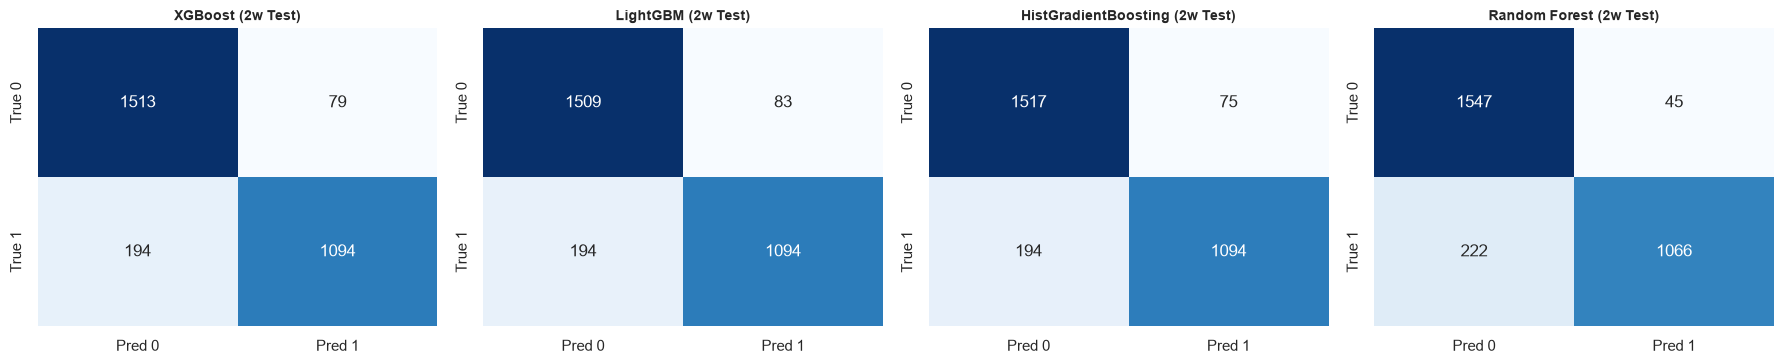

In [6]:
y_test_2w_cls = (test_df["target_2w"] >= 1).astype(int)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes, ["XGBoost", "LightGBM", "HistGradientBoosting", "Random Forest"]):
    cm = confusion_matrix(y_test_2w_cls, test_preds_2w[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], ax=ax)
    ax.set_title(f"{name} (2w Test)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()